# Coded illumination for phase recovery

Companion to `dgs/coded_illumination_design.py`. Idea from B. Jalali, A. Kadambi, V. Roychowdhury, *Physics-AI
Symbiosis*, arXiv:2109.05959, Fig. 3 (paraphrased).

Forward model, 1-D: $y_k = |\mathcal{F}(m_k \odot x)|^2$ for masks $m_k \ge 0$. We ask three questions:
1. Why can't one frame give the phase?
2. How does recovery scale with the number of masks and GS iterations?
3. **Do learned masks still beat random ones once GS has plenty of iterations?** (the open question in the docs)

In [1]:
import sys, pathlib
_root = pathlib.Path.cwd()
_root = _root.parent if (_root.parent / 'dgs').is_dir() else _root
sys.path.insert(0, str(_root))
import numpy as np, torch, matplotlib.pyplot as plt
from dgs import coded_illumination_design as cid

def mean_fid(x, masks, n_iter):
    y = cid._measure(x, masks, torch)
    return float(cid.fidelity(cid.reconstruct(y, masks, n_iter, torch), x).mean())

## 1. One frame hides the phase

In [2]:
N = 32
x = torch.tensor(cid.random_samples(1, N, 5))
x2 = x * torch.exp(1j * torch.linspace(0, 6, N))  # a different object: same amplitude, new phase
# an image-plane camera records |x|^2 = x * conj(x): the phase factor cancels exactly
print('image-plane intensities identical:', bool(torch.allclose(x.abs()**2, x2.abs()**2, atol=1e-6)))
print('but the objects differ (fidelity %.3f, 1.0 = same up to global phase)' % float(cid.fidelity(x2, x)))
assert float(cid.fidelity(x2, x)) < 0.99

image-plane intensities identical: True
but the objects differ (fidelity 0.034, 1.0 = same up to global phase)


## 2. Recovery versus number of masks and GS iterations (random masks)

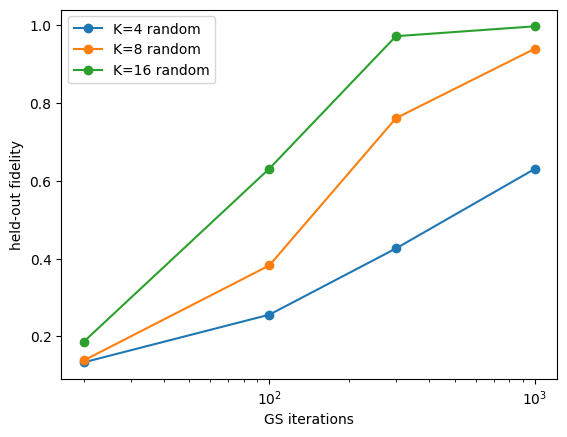

K= 4: [0.133, 0.256, 0.426, 0.63]
K= 8: [0.138, 0.382, 0.761, 0.939]
K=16: [0.186, 0.631, 0.972, 0.997]


In [3]:
torch.manual_seed(0)
xte = torch.tensor(cid.random_samples(64, N, 11))
iters = [20, 100, 300, 1000]
fig, ax = plt.subplots()
curves = {}
for K in (4, 8, 16):
    m = cid._normalize(0.5 * torch.randn(K, N), torch)
    curves[K] = [mean_fid(xte, m, it) for it in iters]
    ax.plot(iters, curves[K], 'o-', label='K=%d random' % K)
ax.set_xscale('log'); ax.set_xlabel('GS iterations'); ax.set_ylabel('held-out fidelity'); ax.legend(); plt.show()
for K, c in curves.items(): print('K=%2d:' % K, [round(v, 3) for v in c])

## 3. Learned versus random masks as GS gets more iterations

Masks are trained with only 20 unrolled iterations (cheap gradients), then **evaluated at up to 1000 iterations**.

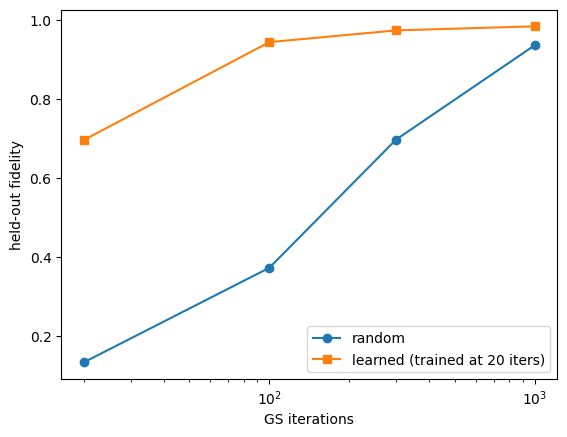

iterations: [20, 100, 300, 1000]
random : [0.133, 0.373, 0.698, 0.937]
learned: [0.697, 0.945, 0.975, 0.985]


In [4]:
K = 8
res = cid.train_masks(K=K, seed=0, steps=150, n_iter=20)
learned = torch.tensor(res['learned']); rand = torch.tensor(res['random'])
L = [mean_fid(xte, learned, it) for it in iters]
R = [mean_fid(xte, rand, it) for it in iters]
fig, ax = plt.subplots()
ax.plot(iters, R, 'o-', label='random'); ax.plot(iters, L, 's-', label='learned (trained at 20 iters)')
ax.set_xscale('log'); ax.set_xlabel('GS iterations'); ax.set_ylabel('held-out fidelity'); ax.legend(); plt.show()
print('iterations:', iters)
print('random :', [round(v, 3) for v in R])
print('learned:', [round(v, 3) for v in L])
assert L[0] > R[0]                      # the known 20-iteration result

## Takeaways (from the numbers above, K=8, one seed, 64 held-out samples)
- One frame cannot give phase: $x$ and $x e^{i\varphi(r)}$ have identical intensity.
- More masks and more GS iterations both help; plain GS is slow (K=8 random: 0.14 at 20 iterations, 0.94 at 1000).
- Learned masks win **mostly by converging faster**: 0.70 at 20 iterations versus 0.13 for random, but at 1000
  iterations the gap closes to 0.985 versus 0.937. A small advantage remains at every budget tested.
- Limits: one seed, one object family, 1-D, noiseless. No claim about 2-D microscopes or noisy cameras.